# EDA parte 3 — Racionamiento, mezcla de generación, autocorrelación y línea base
**Proyecto:** Pronóstico de demanda y alertas de déficit eléctrico (PGCB, Bangladesh)
**Secciones del reporte:** 5.4, 5.5 y 5.6
**Autor:** Julián Botero

Este notebook responde tres preguntas:
1. **5.4** ¿Cuándo hay racionamiento (años, meses, horas)?
2. **5.5** ¿Con qué fuentes se genera la energía y qué pasa con la mezcla en las horas de racionamiento?
3. **5.6** ¿Qué tanto se parece la demanda a la de horas anteriores (autocorrelación)? ¿Qué error tiene un pronóstico ingenuo (línea base) que el modelo debe superar?

In [1]:
!wget -q -O pgcb.zip "https://archive.ics.uci.edu/static/public/1175/pgcb+hourly+generation+dataset+(bangladesh).zip"
!mkdir -p data && unzip -o -q pgcb.zip -d data && ls -R data

data:
PGCB_date_power_demand.xlsx


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Ruta del archivo de datos
RUTA_DATOS = Path("data/PGCB_date_power_demand.xlsx")
CARPETA_FIG = Path("reports/figuras")
CARPETA_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Carga y limpieza mínima
Se aplica la misma limpieza descrita en la sección 3 del reporte: se dejan solo registros en la hora en punto, se agregan duplicados con la mediana, se marcan como faltantes los atípicos de digitación y las fuentes que aún no existían se rellenan con 0.

In [3]:
df = pd.read_excel(RUTA_DATOS)
df.columns = [c.strip().lower() for c in df.columns]
df["datetime"] = pd.to_datetime(df["datetime"])
print(df.shape)
df.head()

(92650, 15)


,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
0,2015-04-19 22:00:00,6323.0,6323,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
1,2015-04-19 21:00:00,6667.0,6667,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
2,2015-04-19 19:00:00,6897.0,6897,0,4415,1836,161,41,NaN,NaN,444,0,NaN,NaN,NaN
3,2015-04-19 18:30:00,6933.0,6933,0,4423,1862,159,45,NaN,NaN,444,0,NaN,NaN,Evening_Peak
4,2015-04-19 18:00:00,6874.0,6874,0,4319,1892,155,65,NaN,NaN,443,0,NaN,NaN,NaN


In [4]:
FUENTES = ["gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
           "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal"]
NUM = ["demand_mw", "generation_mw", "load_shedding"] + FUENTES

# 1) Solo registros en la hora en punto
df = df[df["datetime"].dt.minute == 0]

# 2) Duplicados de fecha-hora
df = df.groupby("datetime")[NUM].median()

# 3) Serie horaria regular
df = df.asfreq("h")

# 4) Fuentes que aún no existían
df[FUENTES] = df[FUENTES].fillna(0)

# 5) Atípicos de digitación
for col in ["demand_mw", "generation_mw"]:
    ref = df[col].groupby(df.index.hour).transform(
        lambda s: s.rolling(15, center=True, min_periods=5).median())
    atipico = (df[col] < 0.5 * ref) | (df[col] > 1.5 * ref)
    print(col, "atípicos:", int(atipico.sum()))
    df.loc[atipico, col] = np.nan

# 6) Interpolar huecos cortos
df[["demand_mw", "generation_mw"]] = df[["demand_mw", "generation_mw"]].interpolate(limit=3)
df["load_shedding"] = df["load_shedding"].fillna(0).clip(lower=0)
df.loc[df["load_shedding"] > 0.5 * df["demand_mw"], "load_shedding"] = 0  # errores de digitación

df["anio"] = df.index.year
df["mes"] = df.index.month
df["hora"] = df.index.hour
df["hay_racionamiento"] = df["load_shedding"] > 0
print("Rango:", df.index.min(), "a", df.index.max(), "| horas:", len(df))

demand_mw atípicos: 165
generation_mw atípicos: 124
Rango: 2015-04-19 00:00:00 a 2025-06-17 12:00:00 | horas: 89101


## 5.4 Racionamiento: ¿cuándo ocurre?
Se mide de dos formas: el **porcentaje de horas con racionamiento** (frecuencia) y la **energía racionada** en GWh (magnitud; 1 MW durante 1 hora = 1 MWh).

In [5]:
rac_anual = df.groupby("anio").agg(
    pct_horas=("hay_racionamiento", "mean"),
    energia_gwh=("load_shedding", lambda s: s.sum() / 1000),
    max_mw=("load_shedding", "max"))
rac_anual["pct_horas"] = (rac_anual["pct_horas"] * 100).round(1)
rac_anual.round(1)

,pct_horas,energia_gwh,max_mw
anio,,,
2015,0.4,7.6,1810.0
2016,0.4,7.3,387.0
2017,0.0,0.2,90.0
2018,0.1,3.3,1800.0
2019,0.1,2.5,900.0
2020,0.0,4.3,2430.0
2021,0.0,0.6,270.0
2022,25.9,1837.6,5443.0
2023,56.8,2739.6,3419.0


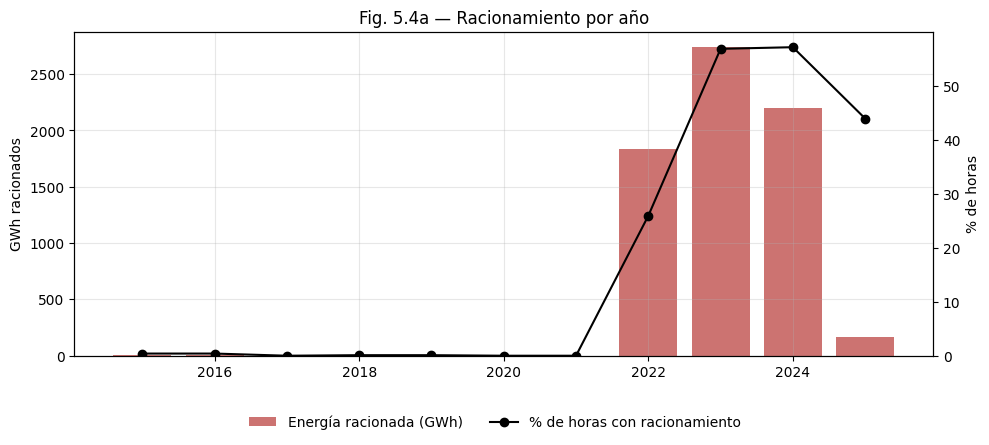

In [6]:
fig, ax1 = plt.subplots()
ax1.bar(rac_anual.index, rac_anual["energia_gwh"], color="#c0504d", alpha=0.8, label="Energía racionada (GWh)")
ax1.set_ylabel("GWh racionados")
ax2 = ax1.twinx()
ax2.plot(rac_anual.index, rac_anual["pct_horas"], color="black", marker="o", label="% de horas con racionamiento")
ax2.set_ylabel("% de horas"); ax2.set_ylim(0, None)
ax2.grid(False)
ax1.set_title("Fig. 5.4a — Racionamiento por año")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(CARPETA_FIG / "fig_5_4a_racionamiento_anual.png", dpi=150, bbox_inches="tight")
plt.show()

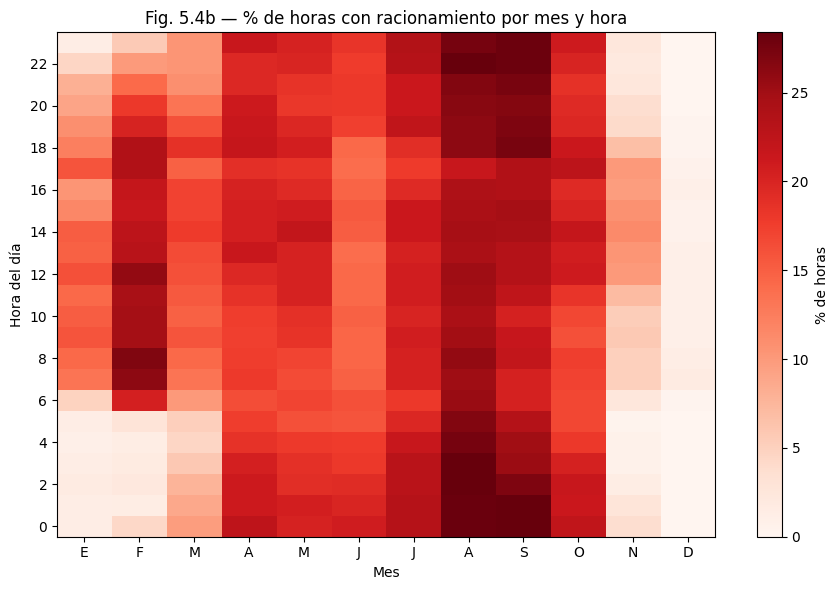

Horas del día con más racionamiento:
hora
14    18.1
12    17.8
18    17.7
13    17.5
15    17.4
dtype: float64

Meses con más racionamiento:
mes
8    25.9
9    24.7
7    21.0
4    19.7
dtype: float64


In [7]:
# Mapa de calor: % de horas con racionamiento según mes y hora del día
mapa = df.pivot_table(index="hora", columns="mes", values="hay_racionamiento", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(mapa, aspect="auto", cmap="Reds", origin="lower")
ax.set_xticks(range(12)); ax.set_xticklabels(["E","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(0, 24, 2))
ax.set_xlabel("Mes"); ax.set_ylabel("Hora del día")
ax.set_title("Fig. 5.4b — % de horas con racionamiento por mes y hora")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% de horas")
fig.tight_layout()
fig.savefig(CARPETA_FIG / "fig_5_4b_mapa_mes_hora.png", dpi=150, bbox_inches="tight")
plt.show()

print("Horas del día con más racionamiento:")
print(mapa.mean(axis=1).sort_values(ascending=False).head(5).round(1))
print("\nMeses con más racionamiento:")
print(mapa.mean(axis=0).sort_values(ascending=False).head(4).round(1))

**Interpretación:** Entre 2015 y 2021 el racionamiento fue casi inexistente (menos del 1 % de las horas). A partir de 2022 se volvió un problema estructural: 26 % de las horas en 2022 y cerca del 57 % en 2023 y 2024, con más de 2.000 GWh racionados por año. Se concentra en los meses de calor y monzón (julio a octubre) y casi desaparece en noviembre y diciembre. En los meses críticos ocurre a casi cualquier hora, con mayor frecuencia entre las 12 y las 18 h. El dato de 2025 solo cubre hasta junio. Esto indica que las alertas del tablero deben ser por hora y considerar el mes del año.

## 5.5 Mezcla de generación
¿Qué fuentes cubren la demanda y cómo ha cambiado su participación? Se presta atención especial al **combustible líquido (diésel / fuel oil)**, que es el respaldo más costoso.

In [8]:
GRUPOS = {
    "Gas": ["gas"],
    "Combustible líquido": ["liquid_fuel"],
    "Carbón": ["coal"],
    "Hidro": ["hydro"],
    "Solar + eólica": ["solar", "wind"],
    "Importaciones": ["india_bheramara_hvdc", "india_tripura", "india_adani", "nepal"],
}
mezcla = pd.DataFrame({g: df[c].clip(lower=0).sum(axis=1) for g, c in GRUPOS.items()})
part_anual = mezcla.groupby(df["anio"]).sum()
part_anual = part_anual.div(part_anual.sum(axis=1), axis=0) * 100
part_anual.round(1)

,Gas,Combustible líquido,Carbón,Hidro,Solar + eólica,Importaciones
anio,,,,,,
2015,70.9,17.8,1.9,2.2,0.0,7.1
2016,66.5,22.3,2.1,1.6,0.0,7.5
2017,63.3,25.3,1.8,1.7,0.0,7.8
2018,65.4,22.5,2.8,1.3,0.0,7.9
2019,70.0,15.7,2.8,1.2,0.1,10.3
2020,65.9,17.2,6.4,1.0,0.1,9.5
2021,61.2,22.9,5.8,0.9,0.3,8.9
2022,37.9,47.4,6.5,0.7,0.4,7.1
2023,51.6,15.5,22.0,0.8,0.9,9.2


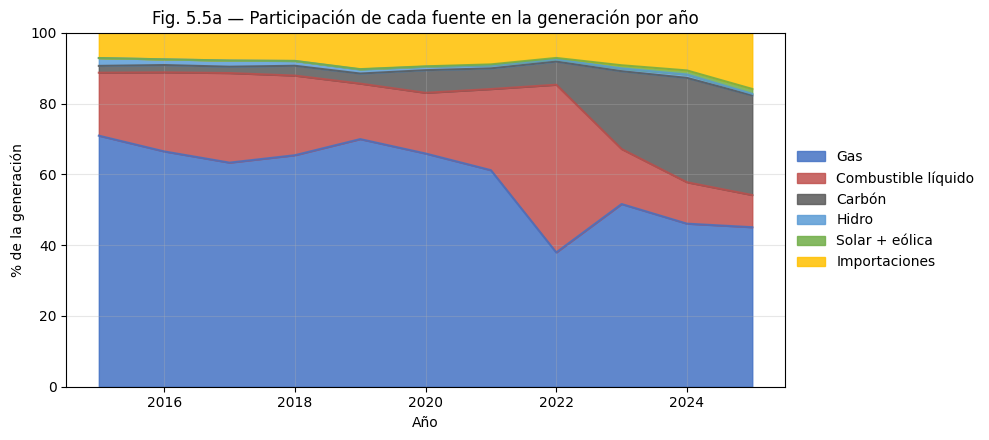

In [9]:
colores = ["#4472c4", "#c0504d", "#595959", "#5b9bd5", "#70ad47", "#ffc000"]
ax = part_anual.plot(kind="area", stacked=True, color=colores, alpha=0.85, figsize=(10, 4.5))
ax.set_ylabel("% de la generación"); ax.set_xlabel("Año"); ax.set_ylim(0, 100)
ax.set_title("Fig. 5.5a — Participación de cada fuente en la generación por año")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_FIG / "fig_5_5a_mezcla_anual.png", dpi=150, bbox_inches="tight")
plt.show()

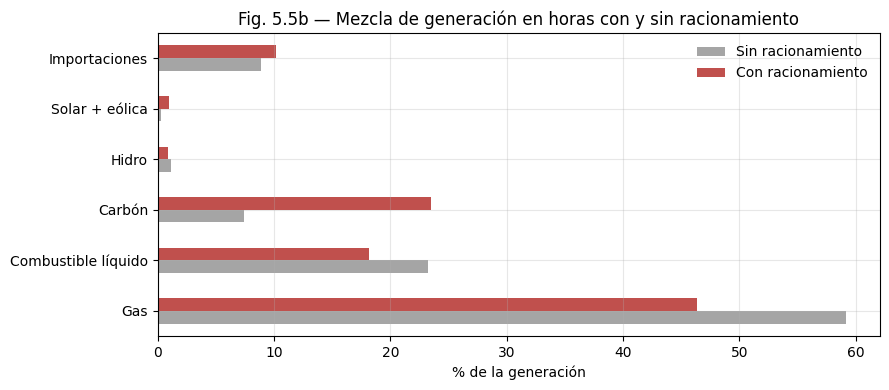

,Gas,Combustible líquido,Carbón,Hidro,Solar + eólica,Importaciones
hay_racionamiento,,,,,,
Sin racionamiento,59.1,23.2,7.4,1.1,0.3,8.8
Con racionamiento,46.4,18.1,23.5,0.9,1.0,10.1


In [10]:
# ¿Cambia la mezcla en las horas con racionamiento?
part_rac = mezcla.groupby(df["hay_racionamiento"]).sum()
part_rac = part_rac.div(part_rac.sum(axis=1), axis=0) * 100
part_rac.index = part_rac.index.map({False: "Sin racionamiento", True: "Con racionamiento"})

ax = part_rac.T.plot(kind="barh", color=["#a5a5a5", "#c0504d"], figsize=(9, 4))
ax.set_xlabel("% de la generación")
ax.set_title("Fig. 5.5b — Mezcla de generación en horas con y sin racionamiento")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_FIG / "fig_5_5b_mezcla_con_sin_racionamiento.png", dpi=150, bbox_inches="tight")
plt.show()
part_rac.round(1)

**Interpretación:** El gas es la fuente principal, pero su participación bajó de 71 % en 2015 a 45 % en 2025. El carbón y las importaciones han ganado espacio desde 2022. El combustible líquido, que es el respaldo más costoso, llegó a 47 % de la generación en 2022, el mismo año en que empezó la crisis de racionamiento. En las horas con racionamiento el gas aporta menos (46 % frente a 59 %), lo que sugiere que la falta de gas es una de las causas del déficit.

## 5.6 Autocorrelación y línea base
La **autocorrelación** mide cuánto se parece la demanda de una hora a la de *k* horas antes. Picos en 24 h (ayer a la misma hora) y 168 h (la semana pasada) justifican usar esos rezagos como variables del modelo.

La **línea base** es un pronóstico ingenuo sin ML. El modelo de la Entrega 2 solo vale la pena si la supera.

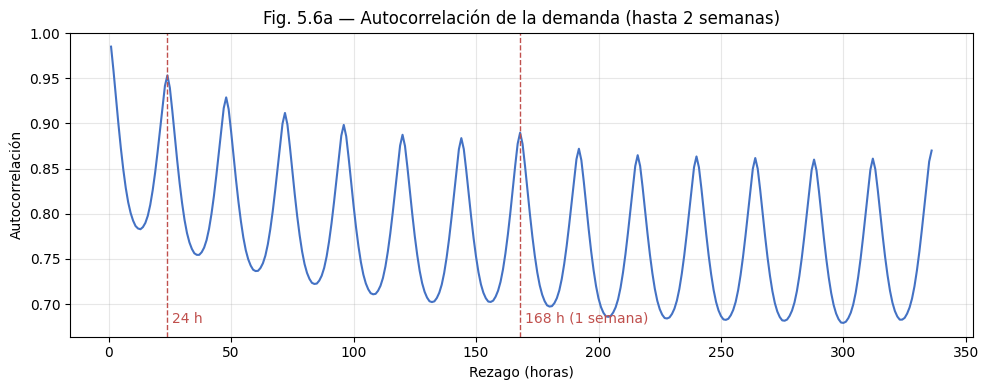

1      0.985
2      0.958
12     0.784
24     0.953
48     0.929
168    0.890
336    0.870
dtype: float64


In [11]:
demanda = df["demand_mw"]
rezagos = range(1, 24 * 14 + 1)  # hasta dos semanas
acf = pd.Series([demanda.autocorr(lag=k) for k in rezagos], index=rezagos)

fig, ax = plt.subplots()
ax.plot(acf.index, acf.values, color="#4472c4")
for k, nombre in [(24, "24 h"), (168, "168 h (1 semana)")]:
    ax.axvline(k, color="#c0504d", ls="--", lw=1)
    ax.text(k + 2, acf.min(), nombre, color="#c0504d")
ax.set_xlabel("Rezago (horas)"); ax.set_ylabel("Autocorrelación")
ax.set_title("Fig. 5.6a — Autocorrelación de la demanda (hasta 2 semanas)")
plt.tight_layout()
plt.savefig(CARPETA_FIG / "fig_5_6a_autocorrelacion.png", dpi=150, bbox_inches="tight")
plt.show()
print(acf.loc[[1, 2, 12, 24, 48, 168, 336]].round(3))

In [12]:
# Líneas base evaluadas en los últimos 12 meses de datos
fin = df.index.max()
prueba = df.loc[fin - pd.DateOffset(years=1):].copy()

pron = pd.DataFrame(index=prueba.index)
pron["Misma hora de ayer (t-24)"] = demanda.shift(24).loc[prueba.index]
pron["Misma hora semana pasada (t-168)"] = demanda.shift(168).loc[prueba.index]
pron["Promedio misma hora últimos 7 días"] = sum(demanda.shift(24 * d) for d in range(1, 8)).loc[prueba.index] / 7

real = prueba["demand_mw"]
def mape(y, yhat):
    m = y.notna() & yhat.notna()
    return (np.abs(y[m] - yhat[m]) / y[m]).mean() * 100
def mae(y, yhat):
    m = y.notna() & yhat.notna()
    return np.abs(y[m] - yhat[m]).mean()

tabla_base = pd.DataFrame({
    "MAPE (%)": {c: mape(real, pron[c]) for c in pron},
    "MAE (MW)": {c: mae(real, pron[c]) for c in pron},
}).round(2)
tabla_base

,MAPE (%),MAE (MW)
Misma hora de ayer (t-24),5.99,680.83
Misma hora semana pasada (t-168),9.79,1163.21
Promedio misma hora últimos 7 días,7.60,882.59


In [13]:
# ¿Qué tan bien detecta la línea base las horas con racionamiento?
# Alerta = demanda pronosticada > generación de la misma hora del día anterior (generación disponible estimada)
gen_estimada = df["generation_mw"].shift(24).loc[prueba.index]
real_rac = prueba["hay_racionamiento"]

filas = {}
for c in pron:
    alerta = pron[c] > gen_estimada
    vp = (alerta & real_rac).sum()
    filas[c] = {
        "Sensibilidad (%)": 100 * vp / real_rac.sum() if real_rac.sum() else np.nan,
        "Precisión (%)": 100 * vp / alerta.sum() if alerta.sum() else np.nan,
    }
tabla_alertas = pd.DataFrame(filas).T.round(1)
print("Horas reales con racionamiento en el periodo de prueba:", int(real_rac.sum()))
tabla_alertas

Horas reales con racionamiento en el periodo de prueba: 4454


,Sensibilidad (%),Precisión (%)
Misma hora de ayer (t-24),79.9,80.0
Misma hora semana pasada (t-168),50.9,47.5
Promedio misma hora últimos 7 días,46.0,47.9


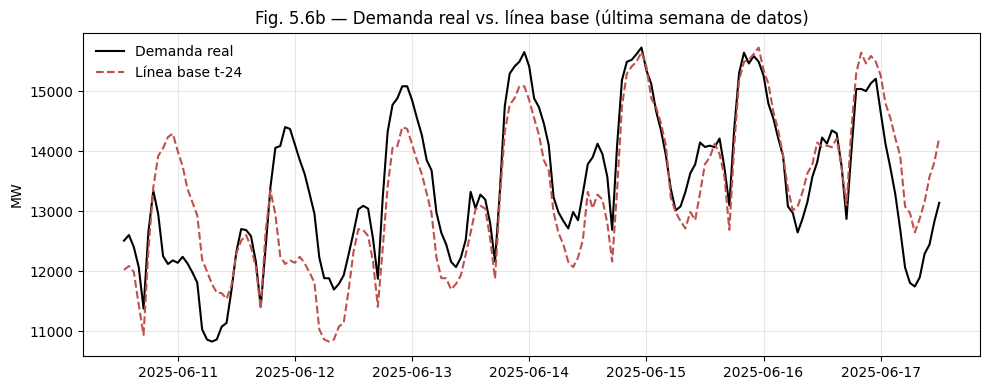

In [14]:
# Una semana de ejemplo: real vs. línea base t-24
semana = prueba.index[-24 * 7:]
fig, ax = plt.subplots()
ax.plot(semana, real.loc[semana], label="Demanda real", color="black")
ax.plot(semana, pron.loc[semana, "Misma hora de ayer (t-24)"], label="Línea base t-24", color="#c0504d", ls="--")
ax.set_ylabel("MW")
ax.set_title("Fig. 5.6b — Demanda real vs. línea base (última semana de datos)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_FIG / "fig_5_6b_linea_base_semana.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** La demanda tiene una autocorrelación muy alta con la hora anterior (0,985) y con la misma hora del día anterior (0,953), y la gráfica repite picos cada 24 horas, lo que confirma un ciclo diario fuerte. Por eso el modelo usará como variables la hora del día, el día de la semana y la demanda de 24 y 168 horas antes. La mejor línea base es repetir la demanda de la misma hora del día anterior, con un MAPE de 5,99 % en los últimos 12 meses. Ese es el valor que el modelo debe superar en la Entrega 2. Esta línea base detecta el 80 % de las horas con racionamiento, y el modelo también debe mejorar esa sensibilidad.